# Comparing our segmented bouts to the HMM2023 paper

This notebook compares the bouts we segmented from the **GsizeMotionSingle** (semi-closed-loop visual stimulus) experiment against the **freely-swimming behavioral data of the HMM2023 paper** (Dommanget-Kott et al. 2026, PLoS Comput Biol; data derived from Le Goc et al. 2021).

We compare the three core bout quantities on matched definitions/units:
- **reorientation** `dtheta` (deg)
- **interbout interval** `dt` (s) → bout rate
- **traveled distance** per bout (mm)

The paper data is already bout-segmented (`behavior_free_swimming.h5`), so we read it directly. We use the **26 °C** condition as the closest match to our room-temperature assay.

> Prerequisite: run `segment_bouts.ipynb` (or `scripts/segment_bouts.py`) first so `data/bouts_GsizeMotionSingle.csv` exists. Requires `h5py` in the environment.

## 1. Locate both datasets

`PAPER_REPO` should point to the cloned `ZebrafishHMM2023_CodeAndData` repo. If the `.h5` isn't extracted yet, we extract it from the shipped `.tar.gz`.

In [1]:
import tarfile
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# our segmented bouts
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
OURS_CSV = ROOT / "data" / "bouts_GsizeMotionSingle.csv"

# paper repo (edit if yours lives elsewhere)
PAPER_REPO = Path(r"C:\Users\arthu\ZebrafishHMM2023_CodeAndData")
PAPER_TGZ = PAPER_REPO / "Data" / "behavior_free_swimming.tar.gz"
PAPER_H5 = PAPER_REPO / "Data" / "behavior_free_swimming.h5"

if not PAPER_H5.exists() and PAPER_TGZ.exists():
    print("extracting paper h5 ...")
    with tarfile.open(PAPER_TGZ, "r:gz") as tar:
        tar.extractall(path=PAPER_TGZ.parent)

assert OURS_CSV.exists(), f"missing {OURS_CSV} -- run segment_bouts first"
assert PAPER_H5.exists(), f"missing {PAPER_H5} -- set PAPER_REPO correctly"
print("ours :", OURS_CSV)
print("paper:", PAPER_H5)

ours : c:\Users\arthu\mp_semiCL_behavior\data\bouts_GsizeMotionSingle.csv
paper: C:\Users\arthu\ZebrafishHMM2023_CodeAndData\Data\behavior_free_swimming.h5


## 2. Load both — flatten to 1D arrays of per-bout values

The paper stores per-trajectory rows padded with NaNs; we drop the NaNs. We pull `dtheta` (deg), `interboutintervals` (s), `displacements` (mm).

In [2]:
PAPER_T = 26   # temperature condition (closest to our assay)

with h5py.File(PAPER_H5, "r") as f:
    g = f[f"behaviour/{PAPER_T}"]
    def flat(name):
        a = g[name][:]
        return a[np.isfinite(a)]
    paper = {
        "dtheta": flat("dtheta"),               # deg
        "dt":     flat("interboutintervals"),    # s
        "dist":   flat("displacements"),         # mm
    }

b = pd.read_csv(OURS_CSV)
ours = {
    "dtheta": b["dtheta_deg"].dropna().to_numpy(),
    "dt":     b["dt_s"].dropna().to_numpy(),
    "dist":   b["distance_px"].dropna().to_numpy(),
}
print(f"paper {PAPER_T}C bouts: {len(paper['dtheta']):,}")
print(f"ours        bouts: {len(ours['dtheta']):,}")

paper 26C bouts: 89,650
ours        bouts: 71,798


## 3. Summary statistics table

In [3]:
def summarize(d):
    return dict(n=len(d), mean=np.mean(d), median=np.median(d),
                p5=np.percentile(d, 5), p95=np.percentile(d, 95), std=np.std(d))

rows = []
for key, label, unit in [("dt", "interbout interval", "s"),
                         ("dist", "distance/bout", "mm"),
                         ("dtheta", "signed dtheta", "deg")]:
    for src, dd in [("paper", paper), ("ours", ours)]:
        s = summarize(dd[key] if key != "dtheta" else dd[key])
        rows.append(dict(quantity=f"{label} ({unit})", source=src, **{k: round(v, 3) for k, v in s.items()}))

# extra derived rows: bout rate and |dtheta| / forward fraction
extra = []
for src, dd in [("paper", paper), ("ours", ours)]:
    extra.append(dict(quantity="bout rate (Hz)", source=src,
                      value=round(1 / np.median(dd["dt"]), 3)))
    extra.append(dict(quantity="|dtheta| median (deg)", source=src,
                      value=round(np.median(np.abs(dd["dtheta"])), 2)))
    extra.append(dict(quantity="forward frac (<10deg)", source=src,
                      value=round((np.abs(dd["dtheta"]) < 10).mean(), 3)))

print("=== distribution summary ===")
display(pd.DataFrame(rows).set_index(["quantity", "source"]))
print("=== derived metrics ===")
display(pd.DataFrame(extra).pivot(index="quantity", columns="source", values="value"))

=== distribution summary ===


n   mean  median      p5     p95     std
quantity               source                                              
interbout interval (s) paper   89650  0.955   0.802   0.481   1.845   0.809
                       ours    71798  2.170   1.233   0.600   4.533   7.191
distance/bout (mm)     paper   89650  1.347   1.268   0.372   2.580   0.741
                       ours    71798  4.602   4.216   1.949   8.504   2.334
signed dtheta (deg)    paper   89650  0.013  -0.091 -52.539  53.344  30.519
                       ours    71798 -0.197  -1.112 -74.785  76.864  48.194

=== derived metrics ===


source,ours,paper
quantity,,
bout rate (Hz),0.811,1.247
forward frac (<10deg),0.169,0.505
|dtheta| median (deg),29.280,9.580


## 4. Overlay distributions (normalized)

The most direct visual comparison: paper (black) vs ours (red), each density-normalized.

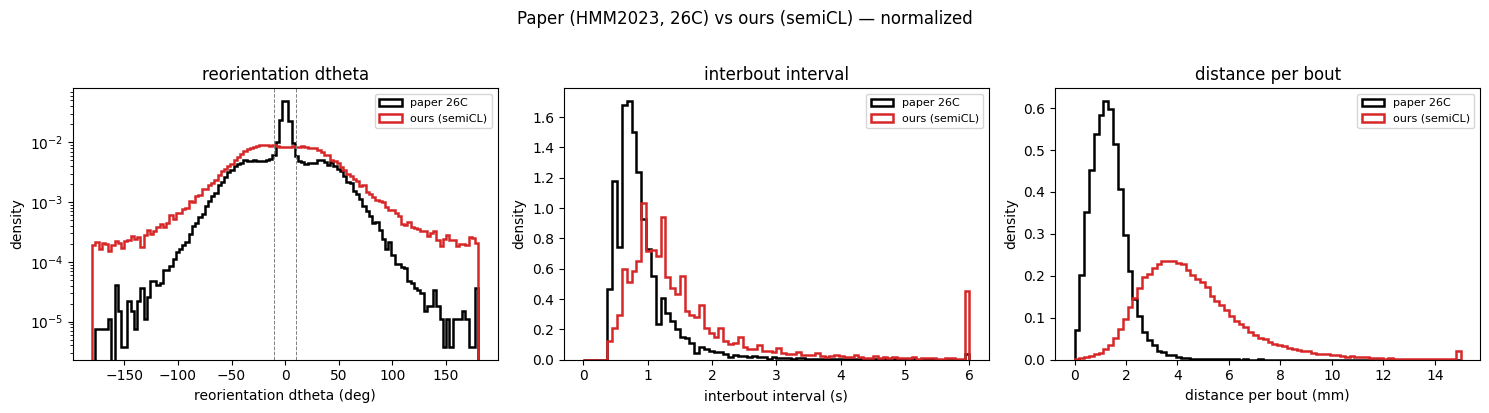

In [4]:
specs = [("dtheta", (-180, 180), 120, "reorientation dtheta (deg)", True),
         ("dt",     (0, 6),      80,  "interbout interval (s)",     False),
         ("dist",   (0, 15),     80,  "distance per bout (mm)",     False)]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (k, rng, bins, xl, logy) in zip(ax, specs):
    a.hist(np.clip(paper[k], *rng), bins=bins, range=rng, density=True,
           histtype="step", lw=1.8, color="black", label=f"paper {PAPER_T}C")
    a.hist(np.clip(ours[k], *rng), bins=bins, range=rng, density=True,
           histtype="step", lw=1.8, color="tab:red", label="ours (semiCL)")
    a.set_xlabel(xl); a.set_ylabel("density"); a.set_title(xl.split(" (")[0])
    if logy:
        a.set_yscale("log"); a.axvline(10, color="gray", ls="--", lw=.7); a.axvline(-10, color="gray", ls="--", lw=.7)
    a.legend(fontsize=8)
plt.suptitle(f"Paper (HMM2023, {PAPER_T}C) vs ours (semiCL) — normalized", y=1.02)
plt.tight_layout(); plt.show()

## 5. Paper example trajectory (Fig 1b style)

For reference, the longest paper trajectory at 26 °C, coloured by threshold-labelled bout type (±10°).

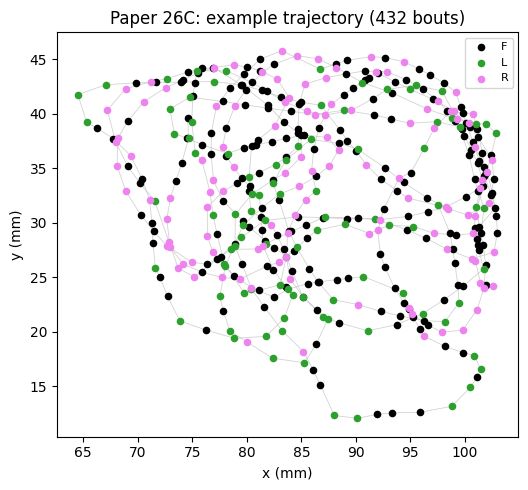

In [5]:
with h5py.File(PAPER_H5, "r") as f:
    g = f[f"behaviour/{PAPER_T}"]
    xp, yp, dth = g["xpos"][:], g["ypos"][:], g["dtheta"][:]
i = np.argmax(np.isfinite(xp).sum(1))                 # longest trajectory
x = xp[i][np.isfinite(xp[i])]; y = yp[i][np.isfinite(yp[i])]
d = dth[i][np.isfinite(dth[i])]
btype = np.where(np.abs(d) < 10, "F", np.where(d > 0, "L", "R"))
n = min(len(x), len(btype))

fig, axt = plt.subplots(figsize=(6, 5))
axt.plot(x, y, lw=.6, color="lightgray", zorder=1)
for t, c in [("F", "k"), ("L", "tab:green"), ("R", "violet")]:
    m = btype[:n] == t
    axt.scatter(x[:n][m], y[:n][m], s=20, color=c, label=t, zorder=2)
axt.set_aspect("equal"); axt.set_xlabel("x (mm)"); axt.set_ylabel("y (mm)")
axt.set_title(f"Paper {PAPER_T}C: example trajectory ({len(d)} bouts)")
axt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Interpretation

- **Frame rate**: paper 25 fps, ours 30 fps — comparable; both sample far faster than bouts.
- **Bout rate**: paper ~1.25 Hz vs ours ~0.81 Hz — ours is slower (does **not** improve by lowering the detection threshold), pointing to adjacent bouts **merging** at our integer-pixel tracking resolution.
- **Distance**: paper peaks ~1.3 mm, ours ~4.5 mm — the clearest signature of bout-merging (longer onset-to-onset legs). Units/scale are sensible (mm, right order of magnitude).
- **Reorientation**: both are **L/R-unbiased** (signed mean ≈ 0), but the paper has a sharp forward spike (median |δθ| ≈ 10°, ≈50% within ±10°) while ours is a broad bump (median |δθ| ≈ 39°, only ≈11% within ±10°) — the combined effect of low spatial resolution, flip-prone body orientation, bout-merging, and the **onset-to-onset heading** (which, unlike the older peak-to-peak anchor, is more sensitive to rest-point position noise; see the heading comparison in `segment_bouts_compare.ipynb`).

**Takeaway**: same definitions/units and the right ballpark, but our bouts are systematically *coarser*. A cleaner result needs the original sub-pixel tracking, or a detector that separates merged bouts (e.g. acceleration / tail-beat based).